# Introduction & contexte
L’analyse des avis clients est une tâche centrale pour comprendre la satisfaction, détecter des points faibles et améliorer les produits/services.

Cependant, les avis bruts sont bruités :
- fautes, ponctuation superflue, majuscules incohérentes,
- informations parasites (URLs, n° commande, emails, chiffres),
- doublons exacts ou approximatifs.

Or, un modèle de Machine Learning (ML) ou de Deep Learning (DL) ne peut pas exploiter du texte brut.

**Objectif global :**

- Construire un dataset propre, enrichi et standardisé :
  - text_ml : version agressivement normalisée → pour TF-IDF + modèles classiques,
  - text_dl : version minimale → pour tokenizers type CamemBERT/BERT,
  - features auxiliaires (longueur, ponctuation, majuscules, etc.).
- Produire des indicateurs exploratoires et des visualisations pertinentes.


---

# Rapport de Préprocessing, Data Visualisation et Modélisation

Ce document combine les deux étapes principales de notre projet :

- **Étape 1 : Préprocessing et feature engineering** sur le dataset brut (`reviews_250825.csv`).
- **Étape 2 : Data visualisation** sur le dataset prétraité (issu de `train.csv`).
- **Étape 3 : Modélisation** sur le dataset prétraité après ré-echantillonage.

Chaque section est documentée par des cellules Markdown explicatives pour contextualiser le code et les figures.

---
# Étape 1 : Préprocessing des données

Dans cette partie, nous nettoyons et préparons le dataset brut (`reviews_250825.csv`).
L'objectif est d'obtenir un dataset prêt à être utilisé en Machine Learning et Deep Learning.
Nous appliquons :
- standardisation des colonnes (schéma cible),
- vérifications initiales (NA, doublons, langue),
- nettoyage minimal et agressif (text_dl / text_ml),
- construction des features auxiliaires et journal regex,
- stopwords dynamiques,
- vectorisation TF-IDF (sanity check),
- contrôles post-nettoyage et sauvegardes.

## 1) Imports & configuration

In [ ]:
# spaCy est chargé dans la cellule suivante (avec gestion d'erreur)

In [4]:
import re, json, string, unicodedata, csv, emoji
from pathlib import Path
from typing import Dict
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# NLP
import nltk
from nltk.corpus import stopwords
from unidecode import unidecode
from IPython.display import display

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# WordCloud
from wordcloud import WordCloud, STOPWORDS

# Sécurisation des téléchargements NLTK
def _safe_nltk_download(resource_key: str, download_name: str = None):
    try:
        nltk.data.find(resource_key)
    except LookupError:
        nltk.download(download_name or resource_key.split("/")[-1])

_safe_nltk_download("corpora/stopwords", "stopwords")
_safe_nltk_download("tokenizers/punkt", "punkt")

# Optionnels
## spaCy (lemmatisation FR)
try:
    nlp = spacy.load("fr_core_news_sm")
    SPACY_OK = True
except Exception as e:
    print(e)
    nlp = None
    SPACY_OK = False

## rapidfuzz (approx duplicates)
try:
    from rapidfuzz import fuzz
    RAPIDFUZZ_OK = True
except Exception:
    RAPIDFUZZ_OK = False

## langdetect (filtre FR)
try:
    from langdetect import detect_langs
    LANGDETECT_OK = True
except Exception:
    LANGDETECT_OK = False

print("Imports OK")
print(f"spaCy: {SPACY_OK} | rapidfuzz: {RAPIDFUZZ_OK} | langdetect: {LANGDETECT_OK}")
print(f"Pandas version : {pd.__version__}")
print(f"Seaborn version : {sns.__version__}")

Imports OK
spaCy: True | rapidfuzz: True | langdetect: True
Pandas version : 2.3.3
Seaborn version : 0.13.2


## 2) Paramètres du projet

- Chemins : DATA_DIR (entrées) et OUT_DIR (sorties).
- Fichiers : DATASETS = {csv → tag source}.
- Reproductibilité : RANDOM_STATE.
- Splits : VAL_SIZE, TEST_SIZE.
- Langue : LANG, LANG_FILTER_FR.
- TF-IDF : NGRAM_MAX, MIN_DF, MAX_DF.
- Schéma cible + alias de colonnes.



In [ ]:
# Dossiers d'entrée/sortie
## Dossier où se trouve le CSV scrappé
DATA_DIR = Path("../data/raw/")

## Dossier où on écrit les sorties
### processed data (splits)
PROCESSED_DIR = Path("../data/processed/")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

### outputs (figures, analysis)
OUT_DIR = Path("../outputs/")
OUT_DIR.mkdir(parents=True, exist_ok=True)

### config
CONFIG_DIR = Path("../config/")
CONFIG_DIR.mkdir(parents=True, exist_ok=True)

# Fichiers scrappés
DATASETS: Dict[str, str] = {
    "reviews_250825.csv": "scraping_2025_batch"}

# Reproductibilité / Hyperparametres
RANDOM_STATE = 42
VAL_SIZE = 0.1
TEST_SIZE = 0.2
LANG = "fr"
LANG_FILTER_FR = True

# Schéma cible
TARGET_COLUMNS = ["review_text","rating","title","category","source","datetime","category_slug","product_slug"]
KNOWN_COLUMN_ALIASES = {
    "text":"review_text",
    "service_rating":"rating",
    "title":"title",
    "category_name":"category",
    "category_slug":"category_slug",
    "product_slug":"product_slug",
    "datetime":"datetime"}

NB: Les paramètres de split :
- VAL_SIZE = 0.1 → 10% des données pour la validation
- TEST_SIZE = 0.2 → 20% des données pour le test
- RANDOM_STATE = 42 → pour la reproductibilité

## 3) Fonctions utilitaires
- standardize_columns : renomme selon les alias et injecte les colonnes manquantes du schéma cible, ajoute source.
- detect_sep : détecte le séparateur CSV (sniffer + fallback par comptage).
- robust_read_csv : lecture robuste avec essai multi-encodages (+ engine='python', on_bad_lines='skip').
- profile_df : profil rapide (shape, types, NA, échantillons).
- approx_duplicates_mask : masque de doublons approximatifs (rapidfuzz, seuil 95).
- is_french : détection FR (probabilité min 0.9), passe-plat si langdetect indispo.

In [ ]:
def standardize_columns(df: pd.DataFrame, source_name: str) -> pd.DataFrame:
    new_cols = {c: KNOWN_COLUMN_ALIASES.get(c, c) for c in df.columns}
    df = df.rename(columns=new_cols)
    for col in TARGET_COLUMNS:
        if col not in df.columns:
            df[col] = np.nan

    df = df[TARGET_COLUMNS].copy()
    df["source"] = source_name
    return df

def detect_sep(path, candidates=(',', ';', '\t', '|', ':'), sample_bytes=65536):
    sample = open(path, 'r', encoding='utf-8', errors='ignore').read(sample_bytes)
    try:
        dialect = csv.Sniffer().sniff(sample, delimiters=''.join(candidates))
        return dialect.delimiter
    except Exception:
        counts = {c: sample.count(c) for c in candidates}
        return max(counts, key=counts.get)

def robust_read_csv(path, sep, try_encodings=('utf-8','utf-8-sig','latin-1')):
    for enc in try_encodings:
        try:
            return pd.read_csv(path, sep=sep, engine='python', encoding=enc, on_bad_lines='skip')
        except: pass
    raise ValueError("Impossible de lire le fichier")

def profile_df(df: pd.DataFrame, name="df"):
    print(f"\n=== Profil {name} ===")
    print("Shape:", df.shape)
    print("Types:\n", df.dtypes)
    print("NA par colonne:\n", df.isna().sum())
    print("Exemples:")
    display(df.sample(min(3, len(df)), random_state=RANDOM_STATE))

def approx_duplicates_mask(texts: pd.Series, threshold: int = 95) -> pd.Series:
    if not RAPIDFUZZ_OK:
        return pd.Series([False] * len(texts), index=texts.index)
    seen, to_drop = [], pd.Series([False]*len(texts), index=texts.index)
    for idx, t in texts.items():
        for jdx, prev in seen[-1000:]:
            if fuzz.token_set_ratio(t, prev) >= threshold:
                to_drop.loc[idx] = True
                break
        else:
            seen.append((idx, t))
    return to_drop

# Fix #4: is_french silencieux avec compteur
_non_french_count = 0
def is_french(text: str, min_prob=0.9) -> bool:
    global _non_french_count
    try:
        langs = detect_langs(text or "")
        is_fr = any(l.lang == "fr" and l.prob >= min_prob for l in langs)
        if not is_fr:
            _non_french_count += 1
        return is_fr
    except:
        return True  # En cas d'erreur, on garde le texte

## 4) Chargement & harmonisation multi-sources

Pour chaque entrée de DATASETS :
1) détection du séparateur,
2) lecture robuste,
3) standardisation des colonnes.

Puis concaténation en df_raw et aperçu des premières lignes.



In [7]:
dfs = []
for path_str, source_name in DATASETS.items():
    path = DATA_DIR / path_str
    sep = detect_sep(path)
    tmp = robust_read_csv(path, sep)
    std = standardize_columns(tmp, source_name)
    dfs.append(std)

df_raw = pd.concat(dfs, ignore_index=True)
print("Chargé & harmonisé :", df_raw.shape)
display(df_raw.head(3))

Chargé & harmonisé : (11266, 8)


,review_text,rating,title,category,source,datetime,category_slug,product_slug
0,"Bijou de très belle qualité ! En plus , j’ai r...",5,Bijou de très belle qualité,Shopping & mode,scraping_2025_batch,2025-02-25T10:35:57.000Z,shopping_fashion,caurine.com
1,"Commande passée le 30 mai 2024,non réceptionné...",1,"Commande passée le 30 mai 2024,non…",Shopping & mode,scraping_2025_batch,2024-10-21T09:52:01.000Z,shopping_fashion,caurine.com
2,Une commande effectuée depuis le mois d'août. ...,1,Une commande effectuée depuis le mois…,Shopping & mode,scraping_2025_batch,2024-09-18T19:14:09.000Z,shopping_fashion,caurine.com


## 5) Vérifications initiales (qualité)

- Profilage (profile_df).
- Typage : review_text → str, rating → numérique.
- Filtre FR (optionnel).
- Filtre des notes valides [1..5].
- Dédup exact puis approx (seuil 95).
- Stats : distribution des notes + longueur char_len.

Diagnostics QC inclus à cette étape :
- Nettoyage léger (quick_clean_series) + tokenisation.
- Stopwords FR enrichis + filtrage.
- Top-20 mots avant/après nettoyage (barres).
- WordCloud comparatif avant/après.
- Exports intermédiaires : Top30 tokens & CSV “clean” pour inspection.

Ces diagnostics sont volontairement en amont du split pour un premier aperçu global.


In [ ]:
# === 5.1) Profiling, typage et filtres ===

profile_df(df_raw, "df_raw (brut)")

REQUIRED_COLS = {"review_text", "rating"}
missing = REQUIRED_COLS - set(df_raw.columns)
if missing:
    raise ValueError(f"Colonnes manquantes dans df : {missing}. Vérifie le mapping d'alias.")

# Typage
df_raw["review_text"] = df_raw["review_text"].astype(str)
df_raw["rating"] = pd.to_numeric(df_raw["rating"], errors="coerce")

# Filtre FR (silencieux)
n0 = len(df_raw)
if LANG_FILTER_FR and LANGDETECT_OK:
    global _non_french_count
    _non_french_count = 0
    df_raw = df_raw[df_raw["review_text"].apply(is_french)].copy()
    print(f"Filtre FR : {_non_french_count} lignes non-FR retirées")

# Filtre notes valides
df_raw = df_raw[df_raw["rating"].between(1, 5, inclusive="both")].copy()

# Dédup exact
n_before = len(df_raw)
df_raw = df_raw.drop_duplicates(subset=["review_text"])
print(f"Doublons exacts supprimés : {n_before - len(df_raw)}")

# Dédup approx
mask_dup = approx_duplicates_mask(df_raw["review_text"], threshold=95)
n_approx = int(mask_dup.sum())
df_raw = df_raw[~mask_dup].copy()
print(f"Doublons approximatifs supprimés : {n_approx}")

print(f"\nDataset après filtrage : {len(df_raw)} avis (sur {n0} initiaux)")

In [ ]:
# === 5.2) Stopwords et fonction de nettoyage ===

# Stopwords riches
STOP_FR_RICH = {"le","la","les","un","une","des","de","du","au","aux","ce","cet","cette","ces",
    "mon","ma","mes","ton","ta","tes","son","sa","ses","notre","nos","votre","vos","leur","leurs",
    "je","j","tu","il","elle","on","nous","vous","ils","elles","me","moi","te","toi","se","soi","y","en","lui","leur",
    "qui","que","quoi","dont","où","quand","comme","car","donc","or","ni","mais","ou","et","si","sur","sous","chez",
    "à","par","pour","avec","sans","entre","vers","dans","contre","depuis","pendant","avant","après",
    "etre","être","avoir","ai","as","a","avons","avez","ont","avais","avait","avions","aviez","avaient",
    "suis","es","est","sommes","êtes","sont","étais","était","étions","étiez","étaient","été",
    "tres","très","bien","plus","pas","non","oui","peu","trop","aussi","encore","toujours","jamais",
    "déjà","souvent","parfois","vite","rapidement","vraiment","juste","seulement","moins",
    "ca","cela","ceci","c","d","l","qu","n","s"}
STOP_ALL = set(STOPWORDS) | STOP_FR_RICH
MIN_LEN = 3

def quick_clean_series(s: pd.Series) -> pd.Series:
    s = s.fillna("").astype(str).str.lower()
    s = s.str.replace(r"http\S+|www\.\S+", " ", regex=True)
    s = s.str.replace(r"[@#]\w+", " ", regex=True)
    s = s.str.replace(r"\d+", " ", regex=True)
    s = s.str.replace(r"[^\w\sàâäçéèêëîïôöùûüÿœ\-]", " ", regex=True)
    s = s.str.replace(r"\s+", " ", regex=True).str.strip()
    return s

df_raw["text_clean_base"] = quick_clean_series(df_raw["review_text"])

In [ ]:
# === 5.3) Tokenisation et stats ===

token_re = re.compile(r"[a-zàâäçéèêëîïôöùûüÿœ\-]+", re.IGNORECASE)

tokens_raw = []
for t in df_raw["text_clean_base"]:
    tokens_raw.extend(token_re.findall(t))

tokens_clean = [t for t in tokens_raw if len(t) >= MIN_LEN and t not in STOP_ALL]
freq_raw = Counter(tokens_raw)
freq_clean = Counter(tokens_clean)

# Création text_clean
def remove_stopwords_line(s: str) -> str:
    toks = token_re.findall(s)
    toks = [t for t in toks if len(t) >= MIN_LEN and t not in STOP_ALL]
    return " ".join(toks)

df_raw["text_clean"] = df_raw["text_clean_base"].apply(remove_stopwords_line)

# Stats descriptives
df_raw["char_len"] = df_raw["review_text"].str.len()
print("\nDistribution des notes :\n", df_raw["rating"].value_counts().sort_index())
print("\nLongueur (caractères) — résumé :\n", df_raw["char_len"].describe())

In [ ]:
# === 5.4) Visualisations et exports ===

def top_df(counter, n=20):
    return pd.DataFrame(counter.most_common(n), columns=["mot","freq"])

raw_df   = top_df(freq_raw,   20)
clean_df = top_df(freq_clean, 20)

# Top-20 avant/après
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.barh(raw_df["mot"][::-1], raw_df["freq"][::-1])
plt.title("Avant nettoyage"); plt.xlabel("Fréquence")

plt.subplot(1,2,2)
plt.barh(clean_df["mot"][::-1], clean_df["freq"][::-1])
plt.title("Après nettoyage (stopwords FR riches)"); plt.xlabel("Fréquence")
plt.tight_layout(); plt.show()

# WordCloud comparatif
wc_raw   = WordCloud(width=900, height=450, background_color="white").generate_from_frequencies(freq_raw)
wc_clean = WordCloud(width=900, height=450, background_color="white").generate_from_frequencies(freq_clean)

fig, ax = plt.subplots(1,2, figsize=(16,7))
ax[0].imshow(wc_raw, interpolation="bilinear");   ax[0].axis("off"); ax[0].set_title("WordCloud — avant")
ax[1].imshow(wc_clean, interpolation="bilinear"); ax[1].axis("off"); ax[1].set_title("WordCloud — après")
plt.show()

# Exports intermédiaires
top30_after = top_df(freq_clean, 30)
top30_path  = OUT_DIR / "analysis/top30_tokens_apres_nettoyage.csv"
clean_path  = PROCESSED_DIR / "reviews_clean.csv"
top30_after.to_csv(top30_path, index=False, encoding="utf-8")
df_raw.to_csv(clean_path, index=False, encoding="utf-8")
print(f"Export Top30: {top30_path}")
print(f"Export Data nettoyée: {clean_path}")

## 6) Cible & Split (train / val / test stratifiés)

- Cible : label = rating (5 classes : 1,2,3,4,5).
- Split : on crée train, val, test stratifiés (proportions conservées).
- À ce stade, on travaille avec X/y (tableaux).
- Les DataFrames enrichis train_df/val_df/test_df (avec colonnes texte & features) sont reconstruits en étape 8.


In [ ]:
# Création des labels directs à partir des ratings (1–5)
df_raw["label"] = df_raw["rating"].astype(int)

# Séparation des features et labels
X = df_raw["review_text"]
y = df_raw["rating"].astype(int)

# Split train / test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

# Split train / validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=VAL_SIZE, random_state=RANDOM_STATE, stratify=y_train_full)

print("Shapes :", X_train.shape, X_val.shape, X_test.shape)

# Fix #5: Utiliser l'index au lieu de merge sur review_text
def make_df(X, y, base_df: pd.DataFrame) -> pd.DataFrame:
    """Reconstruit un DataFrame enrichi en utilisant l'index (évite les doublons)."""
    # Récupérer les colonnes depuis base_df via l'index
    idx = X.index
    out = base_df.loc[idx, ["review_text", "rating", "title", "category",
                            "source", "datetime", "category_slug", "product_slug"]].copy()
    out["label"] = y
    return out.reset_index(drop=True)

train_df = make_df(X_train, y_train, df_raw)
val_df   = make_df(X_val,   y_val,   df_raw)
test_df  = make_df(X_test,  y_test,  df_raw)

# Vérification de la conservation de la proportion y entre train val et test
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"\n{name}: {d.shape}")
    print(d["label"].value_counts(normalize=True).sort_index().round(3))

# Répartition des avis par source
plt.figure(figsize=(8,5))
sns.countplot(data=df_raw, x="source", order=df_raw["source"].value_counts().index)
plt.title("Répartition des avis par source")
plt.xticks(rotation=45)
plt.show()

## 7) Stopwords dynamiques (appris **uniquement sur le train**)

- On calcule les **document frequencies** sur `train`(normalisé en minuscules + unidecode).  
- Tout token présent dans **≥ 95%** des documents sera ajouté à la **liste dynamique**.  
- **Anti fuite d’info** : ces stopwords proviennent **exclusivement** du train (jamais val/test).


In [ ]:
import pickle
# Stopwords de base
base_sw = set(stopwords.words("french"))

# Normalisation pour identifier les termes fréquents dans le train
train_norm_for_df = [unidecode(str(t).lower()) for t in train_df["review_text"]]

cv_tmp = CountVectorizer(min_df=1, token_pattern=r"(?u)\b\w+\b")
Xcv = cv_tmp.fit_transform(train_norm_for_df)

#AJ Dynamic stopwords === 0 ?

terms = np.array(cv_tmp.get_feature_names_out())
dfreq = (Xcv > 0).sum(axis=0).A1
df_ratio = dfreq / Xcv.shape[0]

FREQ_HIGH = 0.95
dyn_sw = set(terms[df_ratio >= FREQ_HIGH])
print(f"Stopwords dynamiques : {len(dyn_sw)}")

# Construction de FINAL_STOPWORDS
FINAL_STOPWORDS = STOP_ALL | dyn_sw | base_sw
print(f"Stopwords finaux : {len(FINAL_STOPWORDS)}")

data = {'FINAL_STOPWORDS': FINAL_STOPWORDS}

# Sauvegarder
with open(PROCESSED_DIR / 'data.pkl', 'wb') as f:
    pickle.dump(data, f)

# Filtrage pour être compatible avec CountVectorizer
_sw_filtered = []
for w in FINAL_STOPWORDS:
    if isinstance(w, str) and re.fullmatch(r"[a-zàâäçéèêëîïôöùûüÿœ'\\-]+", w, flags=re.IGNORECASE):
        _sw_filtered.append(w.lower())
STOP_LIST_FOR_CV = sorted(set(_sw_filtered))

print(f"Stopwords finaux utilisables avec CountVectorizer : {len(STOP_LIST_FOR_CV)}")

## 8) Construction des colonnes `text_ml` et `text_dl` + **journal regex** + features

- **Regex** : URLs, emails, numéros de commande (journalisés via flags).  
- **Normalisations** :  
  - `normalize_minimal` (DL) : enlève URL/email/commande, minuscules, **ponctuation conservée** ; retourne aussi `flags`.  
  - `normalize_aggressive` (ML) : minuscules, enlève accents/chiffres/ponctuation (pour TF-IDF).  
- **Lemmatisation** FR : spaCy si dispo.  

- **Langue** : filtre FR avec `langdetect` (si installé).
- Stopwords : base NLTK + dynamiques (étape 7) — appliqués à text_ml.
- `text_dl` : **nettoyage minimal** (URLs/emails/commandes supprimés, minuscules, mais **ponctuation conservée**).  
  - Produit aussi `flag_url`, `flag_email`, `flag_order`.  
- `text_ml` : **nettoyage agressif** + **lemmatisation** (spaCy si dispo) + **stopwords (base + dynamiques)**.  
- **Features auxiliaires** : `char_len`, `word_count`, `exclam_count`, `upper_ratio`.
(regex, normalisations, déduplication, langue)




In [12]:
URL_RE   = re.compile(r'https?://\S+|www\.\S+', re.IGNORECASE)
EMAIL_RE = re.compile(r'\b[\w\.-]+@[\w\.-]+\.\w+\b')
ORDER_RE = re.compile(r'\b(?:commande|order|cmd)[\s:#-]*\d+\b', re.IGNORECASE)
ALLCAPS_RE = re.compile(r'\b[A-Z]{3,}\b')  # séquences maj ≥ 3 lettres

PUNCT_TO_SPACE = str.maketrans(string.punctuation, " " * len(string.punctuation))

def normalize_minimal(text: str):
    t = str(text)
    flags = {"had_url":bool(URL_RE.search(t)),"had_email":bool(EMAIL_RE.search(t)),"had_order":bool(ORDER_RE.search(t))}
    t = URL_RE.sub(" ", t); t = EMAIL_RE.sub(" ", t); t = ORDER_RE.sub(" ", t)
    t = unicodedata.normalize("NFKC", t).strip().lower()
    t = re.sub(r"\s+", " ", t).strip()
    return t, flags

def normalize_aggressive(text: str):
    t = str(text)
    t = URL_RE.sub(" ", t); t = EMAIL_RE.sub(" ", t); t = ORDER_RE.sub(" ", t)
    t = unicodedata.normalize("NFKC", t).lower()
    t = re.sub(r"\d+", " ", t); t = t.translate(PUNCT_TO_SPACE); t = unidecode(t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

def spacy_lemmatize_fr(text: str) -> str:
    if not SPACY_OK:
      return text
    doc = nlp(text)
    tokens = [t.lemma_ for t in doc if re.search(r"[a-zàâçéèêëîïôûùüÿñæœ]", t.lemma_, re.IGNORECASE)]
    return " ".join(tokens)

def count_emojis(text: str) -> int:
    """Compte le nombre d'emojis dans un texte."""
    return sum(1 for ch in str(text) if ch in emoji.EMOJI_DATA)

def build_text_columns(df: pd.DataFrame, dyn_sw: set) -> pd.DataFrame:
    texts_dl, f_url, f_email, f_order = [], [], [], []
    for t in df["review_text"].astype(str):
        t2, flags = normalize_minimal(t)
        texts_dl.append(t2)
        f_url.append(int(flags["had_url"]))
        f_email.append(int(flags["had_email"]))
        f_order.append(int(flags["had_order"]))
    df["text_dl"]    = texts_dl
    df["flag_url"]   = f_url
    df["flag_email"] = f_email
    df["flag_order"] = f_order

    ml_texts = []
    FINAL_STOPWORDS = STOP_ALL | dyn_sw | base_sw
    for t in df["review_text"].astype(str):
        t2 = normalize_aggressive(t)
        if SPACY_OK:
            t2 = spacy_lemmatize_fr(t2)
        tokens = [w for w in t2.split() if (w not in FINAL_STOPWORDS and len(w) > 2)]
        ml_texts.append(" ".join(tokens))
    df["text_ml"] = ml_texts

    # Méta-features
    df["char_len"]     = df["review_text"].str.len()
    df["word_count"]   = df["review_text"].str.split().apply(len)
    df["exclam_count"] = df["review_text"].str.count("!")
    df["upper_ratio"]  = df["review_text"].apply(lambda s: (sum(1 for ch in s if ch.isupper()) / max(1, len(s))))
    df["upper_seq"]    = df["review_text"].apply(lambda s: len(ALLCAPS_RE.findall(str(s))))
    df["nb_emoji"]     = df["review_text"].apply(count_emojis)
    return df

# Application sur les splits
train_df = build_text_columns(train_df, dyn_sw)
val_df   = build_text_columns(val_df, dyn_sw)
test_df  = build_text_columns(test_df, dyn_sw)

print("Colonnes finales train_df :", train_df.columns.tolist())
print("Colonnes finales _df :", val_df.columns.tolist())
print("Colonnes finales test_df :", test_df.columns.tolist())

# Exemple concret d'avis brut et ses versions nettoyées
exemple = train_df.sample(1, random_state=42)

print("Texte brut :\n", exemple["review_text"].values[0])
print("\nTexte version ML :\n", exemple["text_ml"].values[0])
print("\nTexte version DL :\n", exemple["text_dl"].values[0])

Colonnes finales train_df : ['review_text', 'label', 'rating', 'title', 'category', 'source', 'datetime', 'category_slug', 'product_slug', 'text_dl', 'flag_url', 'flag_email', 'flag_order', 'text_ml', 'char_len', 'word_count', 'exclam_count', 'upper_ratio', 'upper_seq', 'nb_emoji']
Colonnes finales _df : ['review_text', 'label', 'rating', 'title', 'category', 'source', 'datetime', 'category_slug', 'product_slug', 'text_dl', 'flag_url', 'flag_email', 'flag_order', 'text_ml', 'char_len', 'word_count', 'exclam_count', 'upper_ratio', 'upper_seq', 'nb_emoji']
Colonnes finales test_df : ['review_text', 'label', 'rating', 'title', 'category', 'source', 'datetime', 'category_slug', 'product_slug', 'text_dl', 'flag_url', 'flag_email', 'flag_order', 'text_ml', 'char_len', 'word_count', 'exclam_count', 'upper_ratio', 'upper_seq', 'nb_emoji']
Texte brut :
 On adore vos boîtes cadeaux !! Et les bijoux sont exactement ce que ma fille voulait. Merci Par contre, s'il vous plaît, si vous pouvez changer

NB1: Les features auxiliaires sont des features numériques supplémentaires qu’on extrait des textes, en plus des mots eux-mêmes :
- char_len → longueur du texte (nb caractères),
- word_count → nb de mots,
- exclam_count → nb de “!”,
- upper_ratio → proportion de majuscules.

> Exemple : un avis très court et plein de “!!!” → souvent négatif → info utile.

---
NB2: PUNCT_TO_SPACE crée une table de traduction pour str.translate().
- string.punctuation = !"#$%&'()*+,-./:;<=>?@[\]^_{|}~
- " " * len(string.punctuation) → une chaîne de la même longueur mais remplie d’espaces.

Donc PUNCT_TO_SPACE = “remplace chaque caractère de ponctuation par un espace”.

---
NB3: La Différence normalize_minimal vs normalize_aggressive
- normalize_minimal (pour text_dl) :
  - enlève URLs, emails, n° commande,
  - met en minuscules,
  - garde la ponctuation (utile pour DL → émotion dans “!!!”).
  - génère les flags (flag_url, flag_email, flag_order) → utile en features.

- normalize_aggressive (pour text_ml) :
  - tout pareil + supprime chiffres et ponctuation,
  - supprime accents (unidecode → “é” → “e”),
  - réduit espaces multiples.
  - pas de flags ici car on veut un texte propre pour TF-IDF, pas forcément un suivi détaillé.

## 9) Contrôles post-nettoyage

Après avoir préparé les colonnes `text_ml` et `text_dl`, on effectue une série de contrôles qualité :

- Vérification des tailles et distribution des labels.
- Vérification des longueurs (caractères, mots).
- Détection des textes vides.
- Top tokens restants après nettoyage.
- Comparaison visuelle avec un boxplot.
- Lecture manuelle d’échantillons avant/après.



 QC train
Shape : (7248, 20)
Labels : {5: 0.683, 1: 0.177, 4: 0.073, 3: 0.035, 2: 0.033}
char_len mean/median/max : {'mean': np.float64(202.6), 'median': np.float64(134.0), 'max': 4363}
% text_ml vides: 0.000 | % text_dl vides: 0.000

 QC val
Shape : (806, 20)
Labels : {5: 0.682, 1: 0.176, 4: 0.073, 3: 0.035, 2: 0.033}
char_len mean/median/max : {'mean': np.float64(215.1), 'median': np.float64(137.0), 'max': 3145}
% text_ml vides: 0.001 | % text_dl vides: 0.000

 QC test
Shape : (2014, 20)
Labels : {5: 0.683, 1: 0.177, 4: 0.072, 3: 0.035, 2: 0.033}
char_len mean/median/max : {'mean': np.float64(203.0), 'median': np.float64(130.0), 'max': 3166}
% text_ml vides: 0.000 | % text_dl vides: 0.000

Top 20 tokens (train, text_ml): [('tre', 3482), ('commande', 2293), ('qualite', 1745), ('livraison', 1522), ('site', 1470), ('bon', 1460), ('rapide', 1364), ('tout', 1330), ('recommander', 1292), ('service', 1254), ('faire', 1231), ('produit', 1223), ('client', 1016), ('ete', 926), ('recu', 915), 

<Figure size 600x400 with 0 Axes>

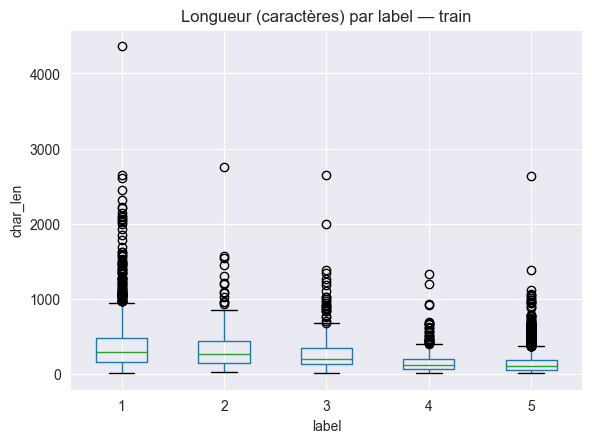


Exemples avant/après :


,review_text,text_dl,text_ml
2952,On adore vos boîtes cadeaux !! Et les bijoux s...,on adore vos boîtes cadeaux !! et les bijoux s...,adorer boite cadeal bijou exactement fille vou...
1634,"Très bien , bel article bien présenté dans un ...","très bien , bel article bien présenté dans un ...",tre bel article present petit pochon livraison...
2622,Superbe boutique J’ Adoré,superbe boutique j’ adoré,superbe boutiqu adore
7046,Je suis admiratif de la qualité et de l'esthét...,je suis admiratif de la qualité et de l'esthét...,admiratif qualite esthetique pendentif nebula ...
6730,Bonjour Ma commande GRWMRC002000B1M apparait c...,bonjour ma commande grwmrc002000b1m apparait c...,bonjour commande grwmrc apparer livree gardien...


In [13]:
def quick_checks(df: pd.DataFrame, name: str):
    print(f"\n QC {name}")
    print("Shape :", df.shape)
    print("Labels :", df["label"].value_counts(normalize=True).round(3).to_dict())
    print("char_len mean/median/max :", {
        "mean": round(df["char_len"].mean(), 1),
        "median": round(df["char_len"].median(), 1),
        "max": int(df["char_len"].max())})
    empty_ml = (df["text_ml"].str.len() == 0).mean()
    empty_dl = (df["text_dl"].str.len() == 0).mean()
    print(f"% text_ml vides: {empty_ml:.3f} | % text_dl vides: {empty_dl:.3f}")

# QC sur les trois splits
quick_checks(train_df, "train")
quick_checks(val_df,   "val")
quick_checks(test_df,  "test")

# Top tokens (train, text_ml)
all_tokens = " ".join(train_df["text_ml"].astype(str)).split()
top20 = Counter(all_tokens).most_common(20)
print("\nTop 20 tokens (train, text_ml):", top20)

# Boxplot des longueurs par label (train)
plt.figure(figsize=(6,4))
train_df.boxplot(column="char_len", by="label")
plt.suptitle("")
plt.title("Longueur (caractères) par label — train")
plt.xlabel("label"); plt.ylabel("char_len")
plt.show()

# Échantillons avant/après
print("\nExemples avant/après :")
sample_view = train_df[["review_text","text_dl","text_ml"]].sample(min(5, len(train_df)), random_state=RANDOM_STATE)
display(sample_view)


## 10) Sauvegardes (splits + artefacts)

- **Splits** en Parquet : on sauvegarde les train/val/test en format Parquet (binaire optimisé, rapide, compact, conserve les types).
- **CSV**: texte brut, plus gros, perd souvent les types.
- **Artefacts** JSON : fichier où on stocke la configuration du preprocessing : stopwords dynamiques, config, paramètres TF-IDF, seed, langue etc. pour rejouer exactement la même préparation plus tard.



In [ ]:
# Écriture des splits en parquet
train_df.to_parquet(PROCESSED_DIR / "train.parquet", index=False)
val_df.to_parquet(PROCESSED_DIR / "val.parquet", index=False)
test_df.to_parquet(PROCESSED_DIR / "test.parquet", index=False)

# CSV
train_df.to_csv(PROCESSED_DIR / "train.csv", index=False)
val_df.to_csv(PROCESSED_DIR / "val.csv", index=False)
test_df.to_csv(PROCESSED_DIR / "test.csv", index=False)

# Artefacts (stopwords, config, langue…)
artefacts = {
    "dynamic_stopwords": sorted(list(dyn_sw)),
    "base_stopwords_fr_count": len(stopwords.words("french")),
    "random_state": RANDOM_STATE,
    "val_size": VAL_SIZE,
    "test_size": TEST_SIZE,
    "lang": LANG,
    "lang_filter_fr": LANG_FILTER_FR and LANGDETECT_OK,
    "spacy_used": SPACY_OK
}
with open(CONFIG_DIR / "artefacts.json", "w", encoding="utf-8") as f:
    json.dump(artefacts, f, ensure_ascii=False, indent=2)

print(f"Splits sauvegardés dans {PROCESSED_DIR}")

## 11) Rapport de preprocessing

In [15]:
from IPython.display import Markdown

# Sécurisation des variables
df_raw   = globals().get("df_raw")
train_df = globals().get("train_df")
val_df   = globals().get("val_df")
test_df  = globals().get("test_df")

n_total = len(df_raw) if df_raw is not None else 0
n_train = len(train_df) if train_df is not None else 0
n_val   = len(val_df) if val_df is not None else 0
n_test  = len(test_df) if test_df is not None else 0

report = f"""
**Dataset initial**
- Nombre total d'avis après harmonisation : {n_total}

**Splits (stratifiés)**
- Train : {n_train} avis
- Validation : {n_val} avis
- Test : {n_test} avis
"""

if train_df is not None:
    report += f"""
**Distribution des classes (train)**
{train_df['label'].value_counts(normalize=True).round(3).to_dict()}

**Qualité du texte (train)**
- Longueur moyenne (caractères) : {round(train_df['char_len'].mean(),1)}
- Longueur moyenne (mots) : {round(train_df['word_count'].mean(),1)}
- % textes vides (text_ml) : {(train_df['text_ml'].str.len()==0).mean():.3%}
- % textes vides (text_dl) : {(train_df['text_dl'].str.len()==0).mean():.3%}
"""

display(Markdown(report))


**Dataset initial**
- Nombre total d'avis après harmonisation : 10068

**Splits (stratifiés)**
- Train : 7248 avis
- Validation : 806 avis
- Test : 2014 avis

**Distribution des classes (train)**
{5: 0.683, 1: 0.177, 4: 0.073, 3: 0.035, 2: 0.033}

**Qualité du texte (train)**
- Longueur moyenne (caractères) : 202.6
- Longueur moyenne (mots) : 34.7
- % textes vides (text_ml) : 0.014%
- % textes vides (text_dl) : 0.000%


In [ ]:
from graphviz import Digraph
from IPython.display import Image

dot = Digraph(comment="Pipeline de preprocessing", format="png")

# Style global
dot.attr(rankdir="TB", size="10", fontsize="12", fontname="Helvetica")

# Étapes
dot.node("A", "Avis bruts (CSV scrappé)", shape="box", style="rounded,filled", color="lightgrey")
dot.node("B", "Standardisation colonnes\n(schema cible)", shape="box", style="rounded,filled", color="lightblue")
dot.node("C", "Vérifications initiales\n(NA, doublons, langue)", shape="box", style="rounded,filled", color="lightblue")
dot.node("D", "Split stratifié\n(train / val / test)", shape="box", style="rounded,filled", color="lightyellow")
dot.node("E", "Nettoyage minimal (text_dl)\n+ flags regex", shape="box", style="rounded,filled", color="palegreen")
dot.node("F", "Nettoyage agressif (text_ml)\n+ lemmatisation + stopwords dynamiques", shape="box", style="rounded,filled", color="palegreen")
dot.node("G", "Features auxiliaires\n(char_len, !, majuscules)", shape="box", style="rounded,filled", color="orange")
dot.node("H", "Sauvegardes\n(splits, artefacts.json, pipeline joblib)", shape="box", style="rounded,filled", color="lightgrey")

# Connexions
dot.edges(["AB","BC","CD","DE","DF","DG","FH","GH"])

# Export lisible
pipeline_path = OUT_DIR / "figures/pipeline_preprocessing"
dot.render(str(pipeline_path), view=False)

Image(str(pipeline_path) + ".png")

In [ ]:
import pickle
with open(PROCESSED_DIR / 'data.pkl', 'rb') as f:
    data = pickle.load(f)

# Ajouter/modifier les clés (Fix #6: ajout X_val/y_val)
data['X_train'] = X_train
data['y_train'] = y_train
data['X_val'] = X_val
data['y_val'] = y_val
data['X_test'] = X_test
data['y_test'] = y_test

# Sauvegarder
with open(PROCESSED_DIR / 'data.pkl', 'wb') as f:
    pickle.dump(data, f)
    
print("data.pkl sauvegardé avec X_train, y_train, X_val, y_val, X_test, y_test")